# Comparar modelos para o mês seguinte
**Fase 4 — Modelação | CRISP-DM**

Agora vamos à pergunta da previsão: **o histórico ajuda a estimar a percentagem sem médico do mês seguinte melhor do que repetir o último valor?**

Não vamos assumir que o modelo mais complexo ganha. A referência simples entra na comparação desde o início e pode ser a escolha final.

Neste notebook escolhemos a abordagem pela **validação temporal**, treinamos novamente com todo o desenvolvimento e guardamos as previsões para o teste. A avaliação do teste fica para o `05_evaluation`; não usamos esse resultado para escolher o modelo.

| Elemento | Definição |
|---|---|
| Dados | `sns_csp_modelacao.csv`, preparado no `03`. |
| Alvo | Percentagem sem médico recalculada das contagens, no mês seguinte. |
| Horizonte | Um mês, dentro do indicador antigo e até junho de 2026. |
| Unidades | 38 séries completas; a correspondência dos dois nomes da Póvoa/Vila do Conde continua pendente. |
| Referência | Repetir a percentagem do mês de origem. |
| Modelos | Regressão linear e Random Forest, com duas configurações previamente definidas. |
| Critério de seleção | Menor MAE na validação, em pontos percentuais. Em empate, preferir a abordagem mais simples. |

**Para executar:** colocar o notebook em `notebooks/`, com o CSV e o manifesto do `03` em `data/output/`. Usar o mesmo kernel Python. Se faltar `scikit-learn`, executar `%pip install scikit-learn` numa célula e reiniciar o kernel se necessário. O código usa ainda `pandas`, `numpy`, `matplotlib` e `joblib`.

## 1. Preparar o ambiente e conferir a entrada

Este notebook funciona sem executar os anteriores na mesma sessão. Cria as pastas de resultados que faltarem e verifica a assinatura do CSV contra o manifesto da preparação.

Ao repetir a execução, atualiza os resultados desta fase. O CSV e o manifesto do `03` são apenas lidos.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

atual = Path.cwd().resolve()
raiz = next((p for p in [atual, *atual.parents]
             if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if raiz is None:
    raise FileNotFoundError("Abrir a pasta do projeto, com notebooks/ e data/.")
PASTA_OUTPUT = raiz / "data" / "output"
PASTA_ANALYTICS = raiz / "data" / "analytics"
PASTA_MODELS = raiz / "data" / "models"
PASTA_DOCS = raiz / "docs"
for pasta in [PASTA_OUTPUT, PASTA_ANALYTICS, PASTA_MODELS, PASTA_DOCS]:
    pasta.mkdir(parents=True, exist_ok=True)

ficheiro_dados = PASTA_OUTPUT / "sns_csp_modelacao.csv"
ficheiro_manifesto = PASTA_OUTPUT / "sns_preparacao_manifesto.json"
if not ficheiro_dados.is_file() or not ficheiro_manifesto.is_file():
    raise FileNotFoundError("Faltam o CSV de modelação ou o manifesto do 03 em data/output/.")
def sha256(f):
    return hashlib.sha256(f.read_bytes()).hexdigest()
assinaturas_entrada = {p.name: sha256(p) for p in [ficheiro_dados, ficheiro_manifesto]}
manifesto = json.loads(ficheiro_manifesto.read_text(encoding="utf-8"))
registo_csv = next((r for r in manifesto["outputs"] if r["ficheiro"] == ficheiro_dados.name), None)
if registo_csv is None or sha256(ficheiro_dados) != registo_csv["sha256"]:
    raise ValueError("O CSV não corresponde ao manifesto. Rever ou voltar a executar o 03.")

dados = pd.read_csv(ficheiro_dados, parse_dates=["mes", "mes_alvo"])
if len(dados) != manifesto["linhas_modelacao"]:
    raise ValueError("A quantidade de linhas difere do manifesto do 03.")

def guardar_csv(tabela, nome, pasta=PASTA_ANALYTICS):
    tabela.to_csv(pasta / nome, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")

def guardar_grafico(fig, nome):
    fig.tight_layout()
    fig.savefig(PASTA_ANALYTICS / nome, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Linhas preparadas:", len(dados))
print("scikit-learn:", sklearn.__version__)

Linhas preparadas: 988
scikit-learn: 1.9.1


## 2. Definir as variáveis e separar os períodos

Usamos uma lista explícita de variáveis do manifesto. Nunca fazemos `X = dados.drop(alvo)`, porque isso deixaria entrar campos como o mês-alvo, a identificação do conjunto ou a previsão de referência.

Vamos retirar `variacao_sem_medico_pp` dos dois modelos: é exatamente a percentagem atual menos a percentagem do mês anterior, que já entram como variáveis. Esta escolha é feita pela relação entre os campos, sem consultar o teste. Mesmo assim, as restantes medidas históricas estão relacionadas; os coeficientes da regressão não serão interpretados como efeitos causais.

| Bloco | Meses-alvo | Uso |
|---|---|---|
| Treino inicial | Maio de 2024 a junho de 2025 | Ajustar os modelos e os seus transformadores. |
| Validação | Julho a dezembro de 2025 | Comparar e escolher a abordagem/configuração. |
| Desenvolvimento completo | Maio de 2024 a dezembro de 2025 | Treinar novamente depois da seleção. |
| Teste reservado | Janeiro a junho de 2026 | Gerar previsões agora; avaliar no `05`. |

A separação é pelo **mês-alvo**. Para prever janeiro de 2026, usamos os dados de dezembro de 2025. Não há divisão aleatória de linhas.

In [2]:
ALVO = manifesto["alvo"]
NUMERICAS = [c for c in manifesto["variaveis_numericas_permitidas"]
             if c != "variacao_sem_medico_pp"]
CATEGORICAS = manifesto["variaveis_categoricas_permitidas"]
VARIAVEIS = NUMERICAS + CATEGORICAS
CHAVE = ["regiao_saude", "unidade_fonte", "mes"]
PROIBIDAS = {ALVO, "mes_alvo", "conjunto", "previsao_ultimo_valor_pct", "unidade_fonte"}
if set(VARIAVEIS) & PROIBIDAS:
    raise ValueError("A lista de variáveis inclui informação que não deve entrar no modelo.")
if dados[VARIAVEIS + [ALVO, "mes", "mes_alvo"]].isna().any().any():
    raise ValueError("Há valores em falta nos campos necessários.")
if dados.duplicated(CHAVE).any() or not dados["mes_alvo"].eq(dados["mes"] + pd.offsets.MonthBegin(1)).all():
    raise ValueError("Chaves duplicadas ou alvo fora do mês seguinte.")
if not np.isfinite(dados[NUMERICAS + [ALVO]].to_numpy()).all():
    raise ValueError("Há valores numéricos não finitos.")

INICIO_TESTE = pd.Timestamp(manifesto["inicio_teste_mes_alvo"])
INICIO_VALIDACAO = pd.Timestamp(manifesto["validacao_sugerida_mes_alvo"]["validacao_de"])
if not dados["conjunto"].eq(np.where(dados["mes_alvo"].ge(INICIO_TESTE), "teste", "desenvolvimento")).all():
    raise ValueError("A divisão temporal não corresponde ao manifesto.")
treino = dados.loc[dados["mes_alvo"].lt(INICIO_VALIDACAO)].copy()
validacao = dados.loc[dados["mes_alvo"].ge(INICIO_VALIDACAO) & dados["mes_alvo"].lt(INICIO_TESTE)].copy()
desenvolvimento = dados.loc[dados["mes_alvo"].lt(INICIO_TESTE)].copy()
teste = dados.loc[dados["mes_alvo"].ge(INICIO_TESTE)].copy()
blocos = {"treino_inicial": treino, "validacao": validacao,
          "desenvolvimento_completo": desenvolvimento, "teste_reservado": teste}
if any(t.empty for t in blocos.values()):
    raise ValueError("Há um bloco temporal vazio.")
if not treino["mes_alvo"].max() < validacao["mes_alvo"].min() < teste["mes_alvo"].min():
    raise ValueError("Os períodos não estão corretamente ordenados.")
divisao = pd.DataFrame([{
    "bloco": nome, "linhas": len(t), "unidades": t["unidade_fonte"].nunique(),
    "primeiro_mes_alvo": t["mes_alvo"].min(), "ultimo_mes_alvo": t["mes_alvo"].max(),
} for nome, t in blocos.items()])
guardar_csv(divisao, "04_divisao_temporal.csv")
display(divisao)
display(pd.DataFrame({"variavel_permitida": VARIAVEIS}))

,bloco,linhas,unidades,primeiro_mes_alvo,ultimo_mes_alvo
0,treino_inicial,532,38,2024-05-01,2025-06-01
1,validacao,228,38,2025-07-01,2025-12-01
2,desenvolvimento_completo,760,38,2024-05-01,2025-12-01
3,teste_reservado,228,38,2026-01-01,2026-06-01


,variavel_permitida
0,inscritos
1,sem_medico_pct
2,sem_medico_opcao_pct
3,sem_medico_pct_lag1
4,sem_medico_pct_lag3
5,sem_medico_pct_media3
6,variacao_inscritos_pct
7,regiao_sem_medico_pct
8,regiao_saude


## 3. Definir os candidatos antes de comparar resultados

A regressão linear é uma primeira tentativa simples de relacionar a cobertura futura com as variáveis atuais e históricas. Normalizamos as variáveis numéricas usando apenas o treino.

A Random Forest permite relações não lineares. Vamos comparar duas configurações limitadas, em vez de testar muitas combinações num histórico curto. As árvores não precisam da mesma normalização. A semente fixa torna o treino repetível no mesmo ambiente.

| Candidato | Configuração |
|---|---|
| Último valor | Previsão igual à percentagem do mês de origem; sem treino. |
| Regressão linear | Variáveis numéricas normalizadas e região codificada. |
| Random Forest A | 150 árvores, profundidade máxima 6, pelo menos 5 linhas por folha. |
| Random Forest B | 150 árvores, profundidade máxima 10, pelo menos 3 linhas por folha. |

A região é codificada em colunas numéricas. Os transformadores ficam dentro de uma `Pipeline`: no treino inicial aprendem apenas com o treino inicial, e no treino final apenas com o desenvolvimento. Não ajustamos nada com o teste.

Como o alvo é uma percentagem, definimos já que as previsões serão limitadas a 0–100. Guardamos também a previsão antes desse limite, para verificar se a regra foi aplicada. Não mudamos esta regra depois de ver os erros.

Documentação: [Pipeline e ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) e [prevenção de fuga de informação](https://scikit-learn.org/stable/common_pitfalls.html).

In [3]:
SEMENTE = 42

def construir_pipeline(estimador, normalizar=False):
    numerico = StandardScaler() if normalizar else "passthrough"
    preparacao = ColumnTransformer([
        ("numericas", numerico, NUMERICAS),
        ("regiao", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ], remainder="drop")
    return Pipeline([("preparacao", preparacao), ("modelo", estimador)])

candidatos = {
    "regressao_linear": construir_pipeline(LinearRegression(), normalizar=True),
    "random_forest_a": construir_pipeline(RandomForestRegressor(
        n_estimators=150, max_depth=6, min_samples_leaf=5, random_state=SEMENTE, n_jobs=1)),
    "random_forest_b": construir_pipeline(RandomForestRegressor(
        n_estimators=150, max_depth=10, min_samples_leaf=3, random_state=SEMENTE, n_jobs=1)),
}
ROTULOS = {"ultimo_valor": "Último valor", "regressao_linear": "Regressão linear",
           "random_forest_a": "Random Forest A", "random_forest_b": "Random Forest B"}
# A ordem também define a preferência por simplicidade quando o MAE empata.
ORDEM = {"ultimo_valor": 0, "regressao_linear": 1, "random_forest_a": 2, "random_forest_b": 3}

def metricas(observado, previsto):
    observado = np.asarray(observado, dtype=float)
    previsto = np.asarray(previsto, dtype=float)
    return {
        "mae_pp": float(mean_absolute_error(observado, previsto)),
        "rmse_pp": float(np.sqrt(mean_squared_error(observado, previsto))),
        "vies_pp": float(np.mean(previsto - observado)),
    }

print("Candidatos definidos antes do treino:", ", ".join(ROTULOS))

Candidatos definidos antes do treino: ultimo_valor, regressao_linear, random_forest_a, random_forest_b


## 4. Treinar e comparar na validação

O **MAE** é o erro absoluto médio em pontos percentuais. Se a percentagem observada for 12% e a previsão 13,5%, o erro absoluto é 1,5 pontos percentuais.

O RMSE dá mais peso a erros grandes. O viés mostra a tendência média: positivo significa sobrestimar, negativo significa subestimar. A seleção usa o MAE; as restantes métricas ajudam a perceber o resultado.

O erro de treino serve para observar a diferença face à validação. Um treino muito bom não basta para escolher o modelo.

,candidato,bloco,linhas,mae_pp,rmse_pp,vies_pp,previsoes_limitadas
0,ultimo_valor,treino,532,0.7005,1.1023,-0.0350,0
1,ultimo_valor,validacao,228,0.6893,1.2696,0.1995,0
2,regressao_linear,treino,532,0.7003,1.0769,0.0004,2
3,regressao_linear,validacao,228,0.7308,1.2913,0.3426,0
4,random_forest_a,treino,532,0.5791,0.8736,-0.0077,0
5,random_forest_a,validacao,228,0.8650,1.3197,0.4010,0
6,random_forest_b,treino,532,0.4433,0.6921,-0.0033,0
7,random_forest_b,validacao,228,0.8612,1.3207,0.4167,0


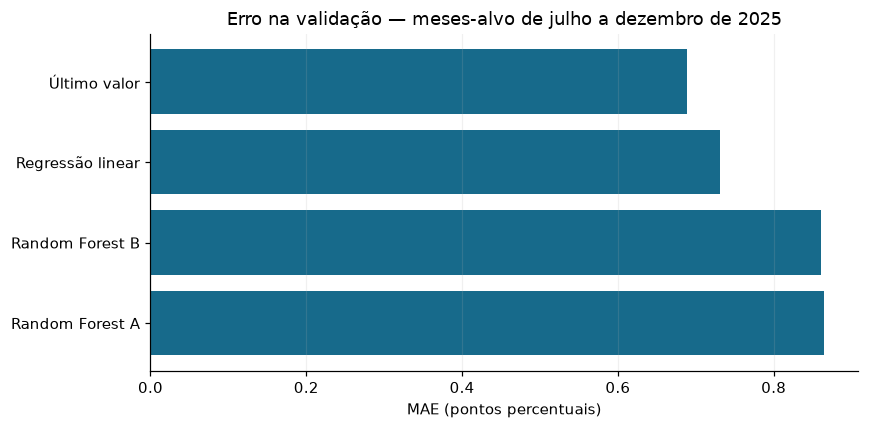

In [4]:
resultados = []
ajustados_iniciais = {}
previsoes_validacao = validacao[CHAVE + ["mes_alvo", ALVO]].copy()
previsoes_validacao = previsoes_validacao.rename(columns={ALVO: "observado_pct"})

for nome in ["ultimo_valor", *candidatos]:
    if nome == "ultimo_valor":
        bruto_treino = treino["sem_medico_pct"].to_numpy()
        bruto_val = validacao["sem_medico_pct"].to_numpy()
    else:
        pipeline = clone(candidatos[nome])
        pipeline.fit(treino[VARIAVEIS], treino[ALVO])
        ajustados_iniciais[nome] = pipeline
        bruto_treino = pipeline.predict(treino[VARIAVEIS])
        bruto_val = pipeline.predict(validacao[VARIAVEIS])
    previsto_treino = np.clip(bruto_treino, 0, 100)
    previsto_val = np.clip(bruto_val, 0, 100)
    previsoes_validacao[f"prev_{nome}_pct"] = previsto_val
    previsoes_validacao[f"prev_{nome}_bruta_pct"] = bruto_val
    for bloco, observado, previsto, bruto_prev in [
        ("treino", treino[ALVO], previsto_treino, bruto_treino),
        ("validacao", validacao[ALVO], previsto_val, bruto_val),
    ]:
        resultados.append({"candidato": nome, "bloco": bloco, "linhas": len(observado),
                           **metricas(observado, previsto),
                           "previsoes_limitadas": int(((bruto_prev < 0) | (bruto_prev > 100)).sum())})

metricas_desenvolvimento = pd.DataFrame(resultados)
tabela_validacao = metricas_desenvolvimento.loc[metricas_desenvolvimento["bloco"].eq("validacao")].copy()
tabela_validacao["ordem_simplicidade"] = tabela_validacao["candidato"].map(ORDEM)
tabela_validacao = tabela_validacao.sort_values(["mae_pp", "ordem_simplicidade"]).reset_index(drop=True)
guardar_csv(metricas_desenvolvimento, "04_metricas_treino_validacao.csv")
guardar_csv(previsoes_validacao, "sns_previsoes_validacao.csv", PASTA_OUTPUT)
display(metricas_desenvolvimento.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
rotulos = [ROTULOS[x] for x in tabela_validacao["candidato"]]
ax.barh(rotulos[::-1], tabela_validacao["mae_pp"].to_numpy()[::-1], color="#176a8b")
ax.set(title="Erro na validação — meses-alvo de julho a dezembro de 2025",
       xlabel="MAE (pontos percentuais)")
ax.grid(axis="x", alpha=0.18)
guardar_grafico(fig, "04_mae_validacao.png")

## 5. Fixar a seleção antes de gerar previsões de teste

Escolhemos a abordagem com menor MAE na validação, incluindo a referência. Se a referência ganhar, fica como abordagem selecionada. Guardamos também o melhor candidato aprendido, para poder comparar o seu comportamento no `05`.

Dentro da família Random Forest, só a configuração com melhor validação avança para o treino final. Assim, o teste vai receber a referência, a regressão linear e a Random Forest já escolhida. Não vamos escolher entre A e B pelo erro de teste.

Nesta versão, um empate numérico até `1e-10` pontos percentuais favorece a abordagem mais simples. Uma diferença pequena fora dessa tolerância permite selecionar pelo critério definido, mas ainda terá de ser discutida na avaliação; não representa automaticamente uma melhoria relevante.

In [5]:
TOLERANCIA_EMPATE = 1e-10
mae_minimo = float(tabela_validacao["mae_pp"].min())
empatados = tabela_validacao.loc[tabela_validacao["mae_pp"].le(mae_minimo + TOLERANCIA_EMPATE)]
selecionado = empatados.sort_values("ordem_simplicidade").iloc[0]["candidato"]
melhor_aprendido = tabela_validacao.loc[tabela_validacao["candidato"].ne("ultimo_valor")].iloc[0]["candidato"]
melhor_rf = tabela_validacao.loc[tabela_validacao["candidato"].str.startswith("random_forest")].iloc[0]["candidato"]
mae_referencia_val = float(tabela_validacao.set_index("candidato").loc["ultimo_valor", "mae_pp"])
mae_selecionado_val = float(tabela_validacao.set_index("candidato").loc[selecionado, "mae_pp"])

selecao = {
    "criterio": "menor MAE na validação temporal; incluir a referência; empate favorece simplicidade",
    "tolerancia_empate_pp": TOLERANCIA_EMPATE,
    "selecionado": selecionado, "melhor_candidato_aprendido": melhor_aprendido,
    "configuracao_rf_selecionada": melhor_rf,
    "mae_referencia_validacao_pp": mae_referencia_val,
    "mae_selecionado_validacao_pp": mae_selecionado_val,
    "ganho_validacao_pp": mae_referencia_val - mae_selecionado_val,
    "variaveis_numericas": NUMERICAS, "variaveis_categoricas": CATEGORICAS,
    "variavel_retirada": {"variacao_sem_medico_pp": "combinação exata da percentagem atual e lag1; ambas já entram"},
    "alvo": ALVO, "semente": SEMENTE,
    "limites_previsao": [0, 100],
    "treino_inicial_ultimo_mes_alvo": treino["mes_alvo"].max().strftime("%Y-%m-%d"),
    "validacao_primeiro_mes_alvo": validacao["mes_alvo"].min().strftime("%Y-%m-%d"),
    "validacao_ultimo_mes_alvo": validacao["mes_alvo"].max().strftime("%Y-%m-%d"),
    "desenvolvimento_ultimo_mes_alvo": desenvolvimento["mes_alvo"].max().strftime("%Y-%m-%d"),
    "teste_primeiro_mes_alvo": teste["mes_alvo"].min().strftime("%Y-%m-%d"),
    "teste_ultimo_mes_alvo": teste["mes_alvo"].max().strftime("%Y-%m-%d"),
    "metricas_teste_calculadas_nesta_fase": False,
}
(PASTA_MODELS / "04_selecao_modelo.json").write_text(json.dumps(selecao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Abordagem selecionada na validação:", ROTULOS[selecionado])
print("Melhor candidato aprendido:", ROTULOS[melhor_aprendido])
print("Random Forest que avança:", ROTULOS[melhor_rf])
print("MAE da referência na validação:", round(mae_referencia_val, 4), "pp")
print("MAE da abordagem selecionada:", round(mae_selecionado_val, 4), "pp")
print("O resultado de teste ainda não foi avaliado.")

Abordagem selecionada na validação: Último valor
Melhor candidato aprendido: Regressão linear
Random Forest que avança: Random Forest B
MAE da referência na validação: 0.6893 pp
MAE da abordagem selecionada: 0.6893 pp
O resultado de teste ainda não foi avaliado.


## 6. Treinar novamente e guardar as previsões

A seleção está fixada. Treinamos a regressão linear e a configuração Random Forest escolhida com todo o desenvolvimento, até ao mês-alvo de dezembro de 2025. Os transformadores são ajustados novamente nesse desenvolvimento.

Os modelos ficam fixos durante os seis meses de teste. Em cada previsão usamos as variáveis do respetivo mês de origem, incluindo valores observados de meses de teste anteriores. É uma avaliação a um mês com origem móvel, não uma previsão de seis meses feita de uma só vez em dezembro.

O ficheiro de previsões inclui o valor observado para a fase seguinte, mas não calculamos aqui os erros de teste. Todas as abordagens recebem as mesmas 228 linhas nesta recolha.

In [6]:
nomes_finais = ["regressao_linear", melhor_rf]
modelos_finais = {}
previsoes_teste = teste[CHAVE + ["mes_alvo", ALVO]].copy().rename(columns={ALVO: "observado_pct"})
previsoes_teste["prev_ultimo_valor_pct"] = teste["sem_medico_pct"].to_numpy()
previsoes_teste["prev_ultimo_valor_bruta_pct"] = teste["sem_medico_pct"].to_numpy()

for nome in nomes_finais:
    pipeline_final = clone(candidatos[nome])
    pipeline_final.fit(desenvolvimento[VARIAVEIS], desenvolvimento[ALVO])
    previsao_bruta = pipeline_final.predict(teste[VARIAVEIS])
    previsoes_teste[f"prev_{nome}_bruta_pct"] = previsao_bruta
    previsoes_teste[f"prev_{nome}_pct"] = np.clip(previsao_bruta, 0, 100)
    modelos_finais[nome] = pipeline_final
    joblib.dump(pipeline_final, PASTA_MODELS / f"04_{nome}.joblib")

previsoes_teste["prev_selecionado_pct"] = previsoes_teste[f"prev_{selecionado}_pct"]
previsoes_teste["abordagem_selecionada"] = selecionado
COLUNAS_PREVISAO = [f"prev_{nome}_pct" for nome in ["ultimo_valor", *nomes_finais]]
if previsoes_teste.duplicated(CHAVE).any() or previsoes_teste[COLUNAS_PREVISAO].isna().any().any():
    raise ValueError("Previsões com duplicados ou valores em falta.")
if not np.isfinite(previsoes_teste[COLUNAS_PREVISAO].to_numpy()).all():
    raise ValueError("Previsões não finitas.")
if not previsoes_teste[COLUNAS_PREVISAO].ge(0).all().all() or not previsoes_teste[COLUNAS_PREVISAO].le(100).all().all():
    raise ValueError("Previsões fora do intervalo definido.")
previsoes_teste = previsoes_teste.sort_values(CHAVE).reset_index(drop=True)
guardar_csv(previsoes_teste, "sns_previsoes_teste.csv", PASTA_OUTPUT)
print("Modelos treinados com", len(desenvolvimento), "linhas.")
print("Previsões de teste guardadas para", len(previsoes_teste), "linhas.")
print("Modelos: data/models/ | Previsões: data/output/sns_previsoes_teste.csv")

Modelos treinados com 760 linhas.
Previsões de teste guardadas para 228 linhas.
Modelos: data/models/ | Previsões: data/output/sns_previsoes_teste.csv


## 7. Conferir o que ficou guardado

Confirmamos que conseguimos carregar os modelos guardados e obter as mesmas previsões. Guardamos as versões das bibliotecas, os parâmetros e as assinaturas dos ficheiros para tornar esta execução rastreável.

No `05`, vamos usar a seleção já registada e avaliar o teste sem voltar a escolher candidatos. Vamos comparar MAE, erros por mês e unidade, viés e situações com erros maiores. A conclusão pode ser manter a referência, mesmo que algum modelo aprendido tenha parecido promissor na validação.

A interpretação fica limitada ao histórico do indicador antigo, às 38 séries completas e à recolha atual, que pode incluir revisões. Esta modelação não produz uma previsão operacional do novo indicador publicado a partir de julho de 2026.

In [7]:
verificacoes = []
for nome in nomes_finais:
    caminho = PASTA_MODELS / f"04_{nome}.joblib"
    carregado = joblib.load(caminho)
    original = modelos_finais[nome].predict(teste[VARIAVEIS])
    restaurado = carregado.predict(teste[VARIAVEIS])
    passou = bool(np.allclose(original, restaurado, rtol=0, atol=1e-10))
    verificacoes.append({"verificacao": f"Modelo guardado reproduz previsões: {nome}", "passou": passou})
verificacoes += [
    {"verificacao": "Entradas do 03 preservadas", "passou": all(sha256(p) == assinaturas_entrada[p.name] for p in [ficheiro_dados, ficheiro_manifesto])},
    {"verificacao": "Mesmas linhas para todas as abordagens de teste", "passou": len(previsoes_teste) == len(teste) and not previsoes_teste[COLUNAS_PREVISAO].isna().any().any()},
    {"verificacao": "Seleção usa apenas métricas de validação", "passou": not selecao["metricas_teste_calculadas_nesta_fase"]},
]
checks = pd.DataFrame(verificacoes)
guardar_csv(checks, "04_verificacoes_execucao.csv")
display(checks)
if not checks["passou"].all():
    raise ValueError("Há verificações que falharam. Rever os resultados antes do 05.")

versoes = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
           "scikit-learn": sklearn.__version__, "joblib": joblib.__version__}
ficheiros_resultado = [PASTA_MODELS / "04_selecao_modelo.json",
                      PASTA_OUTPUT / "sns_previsoes_validacao.csv", PASTA_OUTPUT / "sns_previsoes_teste.csv"]
ficheiros_resultado += [PASTA_MODELS / f"04_{nome}.joblib" for nome in nomes_finais]
execucao = {
    "versoes": versoes, "input_sha256": assinaturas_entrada,
    "blocos": [{"bloco": r["bloco"], "linhas": int(r["linhas"]), "unidades": int(r["unidades"]),
                "primeiro_mes_alvo": r["primeiro_mes_alvo"].strftime("%Y-%m-%d"),
                "ultimo_mes_alvo": r["ultimo_mes_alvo"].strftime("%Y-%m-%d")} for r in divisao.to_dict("records")],
    "parametros": {"regressao_linear": {"fit_intercept": True, "normalizacao": "StandardScaler ajustado no treino"},
                   "random_forest_a": {"n_estimators": 150, "max_depth": 6, "min_samples_leaf": 5, "random_state": SEMENTE, "n_jobs": 1},
                   "random_forest_b": {"n_estimators": 150, "max_depth": 10, "min_samples_leaf": 3, "random_state": SEMENTE, "n_jobs": 1}},
    "selecionado": selecionado, "configuracao_rf_selecionada": melhor_rf,
    "metricas_teste_calculadas": False,
    "resultados_sha256": {str(p.relative_to(raiz)): sha256(p) for p in ficheiros_resultado},
}
(PASTA_MODELS / "04_execucao_modelacao.json").write_text(json.dumps(execucao, ensure_ascii=False, indent=2), encoding="utf-8")
nota = f"""# Fase 4 — Modelação

Entrada: sns_csp_modelacao.csv, preparada no 03 e verificada contra o manifesto.

## Decisões

- Separação por mês-alvo: treino inicial até junho de 2025, validação julho–dezembro de 2025, teste janeiro–junho de 2026. Sem divisão aleatória.
- Variáveis explícitas do manifesto; retirada variacao_sem_medico_pp por ser combinação exata da percentagem atual e lag1. Taxas de consultas, alvo e campos de identificação/avaliação excluídos dos preditores.
- Referência: repetir último valor. Candidatos aprendidos: regressão linear e Random Forest A/B previamente definidos. Configurações e versões no 04_execucao_modelacao.json.
- Transformadores ajustados apenas no treino; após seleção, novo ajuste apenas no desenvolvimento completo.
- Seleção por menor MAE na validação, incluindo a referência. Empate até {TOLERANCIA_EMPATE} pp favorece simplicidade. Previsões limitadas a 0–100 pela regra definida antes da comparação; valores brutos guardados.
- Abordagem selecionada: {selecionado}. Melhor candidato aprendido: {melhor_aprendido}. Configuração Random Forest que avança: {melhor_rf}.
- MAE referência na validação: {mae_referencia_val:.6f} pp. MAE selecionado: {mae_selecionado_val:.6f} pp. Ganho: {mae_referencia_val - mae_selecionado_val:.6f} pp.
- Treino final com {len(desenvolvimento)} linhas; previsões para {len(teste)} linhas de teste, mesmas unidades e meses para as três abordagens finais. Modelos fixos, origens mensais móveis e dados observados até cada origem.
- O teste não foi avaliado nesta fase. A seleção deve ser mantida no 05 mesmo que o ranking no teste mude.

## Ficheiros para o 05

- data/output/sns_previsoes_teste.csv: observados e previsões alinhados por região, unidade, origem e mês-alvo.
- data/models/04_selecao_modelo.json: escolha feita antes de avaliar o teste.
- data/analytics/04_metricas_treino_validacao.csv: resultados usados no desenvolvimento.
- data/models/04_execucao_modelacao.json: configuração, versões e assinaturas.

## Limitações

Só 38 séries completas; nomes estáveis não garantem continuidade territorial. Amostra curta e unidades/meses dependentes. Recolha atual pode conter revisões. Indicador antigo até junho de 2026; não extrapolar para a quebra de definição de julho. Nenhum coeficiente ou importância constitui evidência causal.

Fontes técnicas: [Pipeline](https://scikit-learn.org/stable/modules/compose.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) e [prevenção de fuga de informação](https://scikit-learn.org/stable/common_pitfalls.html).
"""
(PASTA_DOCS / "04_decisoes_modelacao.md").write_text(nota, encoding="utf-8")
print("Modelação concluída. Seleção fixada e previsões prontas para avaliar no 05.")

,verificacao,passou
0,Modelo guardado reproduz previsões: regressao_...,True
1,Modelo guardado reproduz previsões: random_for...,True
2,Entradas do 03 preservadas,True
3,Mesmas linhas para todas as abordagens de teste,True
4,Seleção usa apenas métricas de validação,True


Modelação concluída. Seleção fixada e previsões prontas para avaliar no 05.


## 8. Próximo passo

No `05_evaluation`, vamos responder à pergunta com o período de teste: a abordagem selecionada acrescenta informação face ao último valor? O ganho é consistente entre meses e unidades, ou concentra-se em poucos casos?

Também vamos reunir a avaliação das perguntas e hipóteses descritivas. A previsão é uma parte do projeto; o resultado dos modelos não substitui a análise da cobertura e das diferenças geográficas.

## Próxima fase

[Avançar para o 05 — Avaliação](./05_evaluation.ipynb)